# Automated Selfie System: Smile Detection with a CNN, End to End

A system that takes a selfie automatically when you smile. This notebook walks through the **whole workflow** and explains *why* each step is done:

| Part | What happens | Key question |
|---|---|---|
| 1. Setup | GPU, libraries | |
| 2. Data | Download and **explore** the dataset | What does the model learn from? |
| 3. Training | Preprocess, train LeNet | How does the model learn? |
| 4. Evaluation | Test set, confusion matrix, **error analysis**, thresholds | How good is it, and where does it fail? |
| 5. Benchmark | 5 approaches on the same split | Is a CNN even needed? |
| 6. Deployment test | Your own photos | Does it work outside the dataset? |
| 7. Explainability I | Grad-CAM, LayerCAM, occlusion | *Where* does the model look? |
| 8. Explainability II | LIME, SHAP, faithfulness check | Can we *trust* the explanations? |





## 1. Setup

In [ ]:
!pip install -q lime shap

import tensorflow as tf
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Data: SMILEsmileD


In [ ]:
!git clone -q --depth 1 https://github.com/hromi/SMILEsmileD.git
!rm -rf dataset && mkdir -p dataset
!cp -r SMILEsmileD/SMILEs/positives/positives7 dataset/smiling
!cp -r SMILEsmileD/SMILEs/negatives/negatives7 dataset/not_smiling
!echo "smiling:     $(ls dataset/smiling | wc -l) files"
!echo "not_smiling: $(ls dataset/not_smiling | wc -l) files"

smiling:     3690 files
not_smiling: 9476 files


### 2.1 Explore the data before training
Always look at the data first. Three things to notice:
1. **Class imbalance.**
2. **Framing.**
3. **Quality.**

Image size: (64, 64, 3) | counts: {'smiling': 3690, 'not_smiling': 9476} | majority-class baseline accuracy: 72.0%


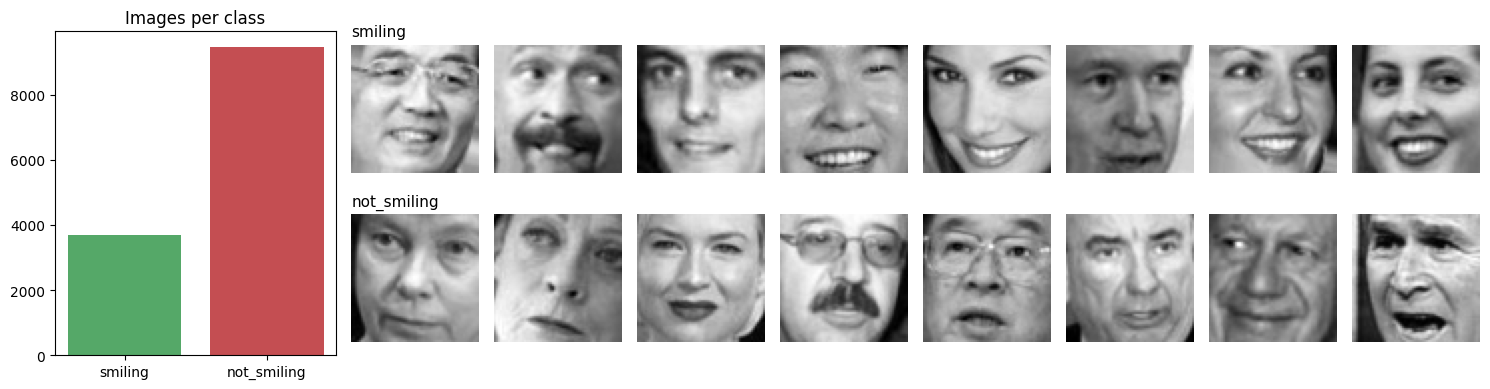

In [ ]:
import os, random, cv2
import numpy as np
import matplotlib.pyplot as plt

counts = {c: len(os.listdir(f"dataset/{c}")) for c in ["smiling", "not_smiling"]}
sample = cv2.imread("dataset/smiling/" + sorted(os.listdir("dataset/smiling"))[0])
print("Image size:", sample.shape, "| counts:", counts,
      f"| majority-class baseline accuracy: {max(counts.values()) / sum(counts.values()):.1%}")

fig, axes = plt.subplots(2, 9, figsize=(15, 4), gridspec_kw={"width_ratios": [2.2] + [1] * 8})
gs = axes[0, 0].get_gridspec()
for ax in axes[:, 0]:
    ax.remove()
bar_ax = fig.add_subplot(gs[:, 0])
bar_ax.bar(counts.keys(), counts.values(), color=["#55A868", "#C44E52"])
bar_ax.set_title("Images per class")

random.seed(0)
for row, cls in enumerate(["smiling", "not_smiling"]):
    for col, f in enumerate(random.sample(os.listdir(f"dataset/{cls}"), 8), start=1):
        img = cv2.imread(f"dataset/{cls}/{f}", cv2.IMREAD_GRAYSCALE)
        if img is not None:
            axes[row, col].imshow(img, cmap="gray")
        axes[row, col].axis("off")
    axes[row, 1].set_title(cls, loc="left", fontsize=11)
plt.tight_layout()
plt.show()

## 3. Training LeNet

### 3.1 What the training script does
**Preprocessing** (must be identical at training and deployment time):
- **Grayscale:** a smile is about shape, not colour; 3× less data.
- **Resize to 28×28:** LeNet's input size; every image must be the same size.
- **÷255:** pixel values 0–1 keep training numerically stable.

**Splitting:** 72% train / 8% validation / 20% test, stratified (same class ratio everywhere). The **test set is used only once, at the very end**, so the final number is honest.

**Against class imbalance and overfitting:**
- **Class weights:** a mistake on the rare *smiling* class counts ~2.5× more.
- **Flip augmentation:** a mirrored smile is still a smile, which doubles the training data for free. It's applied *after* splitting off validation, so no mirrored copy of a training face leaks into validation.
- **Early stopping:** stop when validation loss hasn't improved for 4 epochs, and keep the best epoch's weights.
- **Learning-rate reduction:** halve the step size when progress stalls.

**The model (LeNet):** Conv(20, 5×5) → MaxPool → Conv(50, 5×5) → MaxPool → Flatten → Dense(500) + Dropout(0.5) → Dense(2, softmax). About 1.25M weights, almost all in the first Dense layer.

**How it learns:** for each batch of 64 images, predict, then measure the error with **cross-entropy** (confident mistakes are punished hardest), then **backpropagation** computes how each weight contributed, then the **Adam** optimizer nudges every weight to reduce the error.

In [ ]:
%%writefile train_model.py
"""
train_model.py
Trains a LeNet CNN to classify faces as "smiling" or "not smiling".

Dataset folder structure (e.g. SMILEsmileD dataset):
    dataset/
        smiling/       -> images of smiling faces
        not_smiling/   -> images of non-smiling faces
"""

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

#  Settings
DATASET_DIR = "dataset"
CLASSES = ["not_smiling", "smiling"]   # label 0, label 1
IMG_SIZE = 28
EPOCHS = 30          # upper limit - early stopping usually stops sooner
BATCH_SIZE = 64
MODEL_PATH = "smile_lenet.h5"


#  1. Load and preprocess images
def load_dataset():
    images, labels = [], []

    for label, class_name in enumerate(CLASSES):
        folder = os.path.join(DATASET_DIR, class_name)
        for file in os.listdir(folder):
            img = cv2.imread(os.path.join(folder, file))
            if img is None:
                continue
            gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)   # grayscale
            gray = cv2.resize(gray, (IMG_SIZE, IMG_SIZE))  # 28x28
            images.append(gray)
            labels.append(label)

    X = np.array(images, dtype="float32") / 255.0      # scale to 0-1
    X = X.reshape(-1, IMG_SIZE, IMG_SIZE, 1)           # add channel
    y = np.array(labels)
    return X, y


#  2. Build LeNet
def build_lenet():
    model = Sequential([
        Conv2D(20, (5, 5), padding="same", activation="relu",
               input_shape=(IMG_SIZE, IMG_SIZE, 1)),
        MaxPooling2D((2, 2)),

        Conv2D(50, (5, 5), padding="same", activation="relu"),
        MaxPooling2D((2, 2)),

        Flatten(),
        Dense(500, activation="relu"),
        Dropout(0.5),
        Dense(2, activation="softmax"),
    ])
    model.compile(optimizer="adam",
                  loss="categorical_crossentropy",
                  metrics=["accuracy"])
    return model


#  3. Class weights (handle imbalance)
def get_class_weights(y):
    # weight = total / (num_classes * count_of_class)
    counts = np.bincount(y)
    total = len(y)
    weights = {i: total / (len(counts) * c) for i, c in enumerate(counts)}
    print("Class counts :", dict(enumerate(counts)))
    print("Class weights:", weights)
    return weights


# 4. Plot training curves
def plot_history(history):
    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.plot(history.history["accuracy"], label="train")
    plt.plot(history.history["val_accuracy"], label="val")
    plt.title("Accuracy")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history["loss"], label="train")
    plt.plot(history.history["val_loss"], label="val")
    plt.title("Loss")
    plt.legend()

    plt.tight_layout()
    plt.savefig("training_plot.png")
    plt.show()


#  Main
if __name__ == "__main__":
    print("Loading dataset...")
    X, y = load_dataset()
    print("Total images:", len(X))


    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=42)


    X_train, X_val, y_train, y_val = train_test_split(
        X_train, y_train, test_size=0.1, stratify=y_train, random_state=42)


    X_train = np.concatenate([X_train, np.flip(X_train, axis=2)])
    y_train = np.concatenate([y_train, y_train])
    print("Train:", len(X_train), "| Val:", len(X_val), "| Test:", len(X_test))

    class_weights = get_class_weights(y_train)

    model = build_lenet()
    model.summary()

    callbacks = [

        EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),

        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, verbose=1),
    ]

    history = model.fit(
        X_train, to_categorical(y_train, 2),
        validation_data=(X_val, to_categorical(y_val, 2)),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        class_weight=class_weights,
        callbacks=callbacks,
        shuffle=True,
    )

    # Evaluate
    preds = model.predict(X_test).argmax(axis=1)
    print(classification_report(y_test, preds, target_names=CLASSES))

    model.save(MODEL_PATH)
    print("Model saved to", MODEL_PATH)

    plot_history(history)


Writing train_model.py


Loading dataset...
Total images: 13165
Train: 18956 | Val: 1054 | Test: 2633
Class counts : {0: np.int64(13642), 1: np.int64(5314)}
Class weights: {0: np.float64(0.6947661633191614), 1: np.float64(1.7835905156191194)}
/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
W0000 00:00:1795254836.318493    1748 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
Model: "sequential"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━

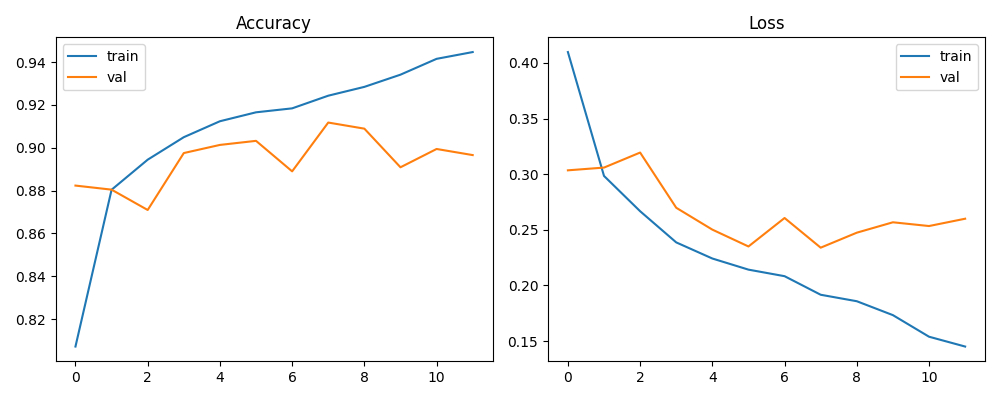

In [ ]:
!python train_model.py

from IPython.display import Image
Image("training_plot.png")

## 4. Evaluation on the untouched test set

The cell below rebuilds **exactly the same test split** as the training script (same `random_state=42`) and evaluates the saved model.

- **Confusion matrix:** where the mistakes are (false smiles vs missed smiles).
- **Precision (smile):** when it says "smile", how often is it right?
- **Recall (smile):** of all real smiles, how many does it catch?
- **F1:** the balance of the two. More honest than accuracy on imbalanced data.

              precision    recall  f1-score   support

 not_smiling      0.954     0.916     0.935      1895
     smiling      0.805     0.888     0.844       738

    accuracy                          0.908      2633
   macro avg      0.880     0.902     0.889      2633
weighted avg      0.912     0.908     0.909      2633



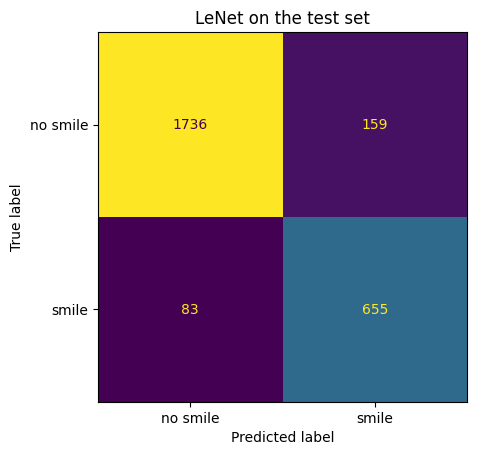

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras.models import load_model
from train_model import load_dataset, CLASSES

X, y = load_dataset()
_, X_test, _, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)  # same split as training

model = load_model("smile_lenet.h5")
probs = model.predict(X_test, verbose=0)[:, 1]          # smile probability per test face
preds = (probs >= 0.5).astype(int)

print(classification_report(y_test, preds, target_names=CLASSES, digits=3))
ConfusionMatrixDisplay(confusion_matrix(y_test, preds), display_labels=["no smile", "smile"]).plot(colorbar=False)
plt.title("LeNet on the test set")
plt.show()

### 4.1 Error analysis: look at the mistakes
Numbers say *how often* the model fails; pictures say *why*. Below are the test faces where the model was **most confidently wrong**. Typical causes: ambiguous expressions (a slight smile), open mouth while talking, unusual lighting, turned heads, or **label noise**.

Look closely: in SMILEsmileD, several of the "confident mistakes" are faces labelled *smiling* that clearly aren't, or labelled *not smiling* while showing a big smile. There, **the model is right and the label is wrong**. Some of the measured error is a limit of the dataset, not of the model.

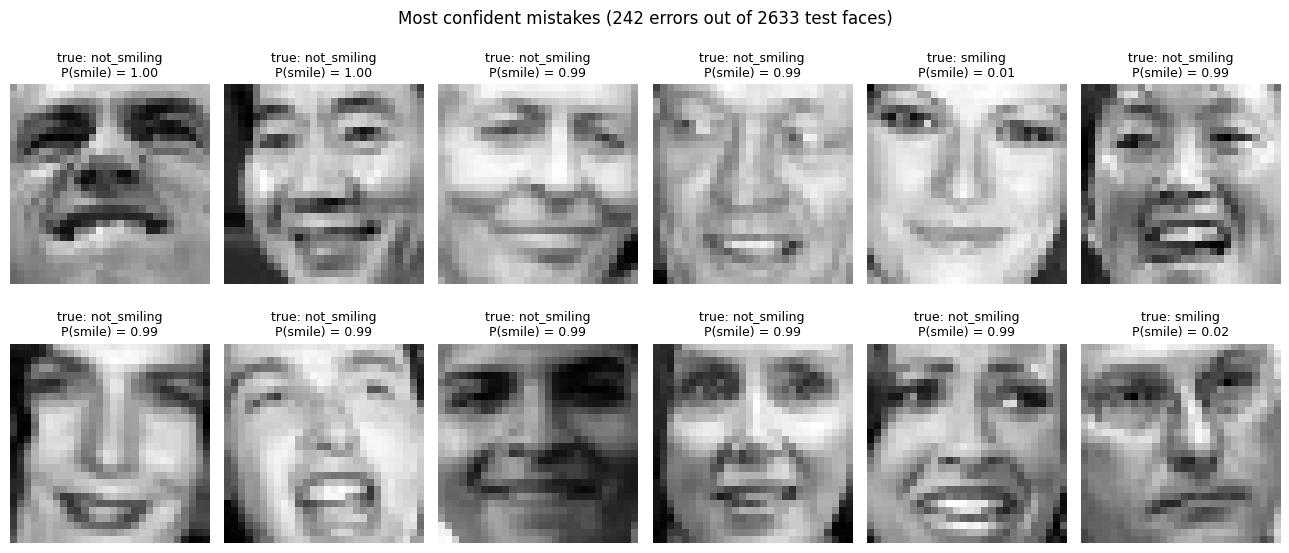

In [ ]:
wrong = np.where(preds != y_test)[0]
worst = wrong[np.argsort(-np.abs(probs[wrong] - 0.5))][:12]     # most confident mistakes first

fig, axes = plt.subplots(2, 6, figsize=(13, 6))
for ax, i in zip(axes.ravel(), worst):
    ax.imshow(X_test[i, ..., 0], cmap="gray")
    ax.set_title(f"true: {CLASSES[y_test[i]]}\nP(smile) = {probs[i]:.2f}", fontsize=9)
    ax.axis("off")
plt.suptitle(f"Most confident mistakes ({len(wrong)} errors out of {len(y_test)} test faces)")
plt.tight_layout()
plt.show()

### 4.2 Choosing the decision threshold
The live app only counts a smile when **P(smile) ≥ 0.80**, not 0.50. Why? A false smile means an **unwanted photo**, which is worse than waiting a moment for a clearer smile. A higher threshold trades **recall** (catching every smile) for **precision** (being sure).

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

rows = []
for t in [0.3, 0.5, 0.6, 0.7, 0.8, 0.9]:
    p = (probs >= t).astype(int)
    rows.append({"threshold": t,
                 "precision (smile)": precision_score(y_test, p),
                 "recall (smile)": recall_score(y_test, p),
                 "F1": f1_score(y_test, p)})
pd.DataFrame(rows).round(3)

,threshold,precision (smile),recall (smile),F1
0,0.3,0.734,0.940,0.824
1,0.5,0.805,0.888,0.844
2,0.6,0.838,0.867,0.852
3,0.7,0.869,0.847,0.858
4,0.8,0.894,0.791,0.840
5,0.9,0.930,0.703,0.801


## 5. Benchmark: is a CNN even needed?

A model is only impressive compared with alternatives. All five approaches are trained and tested on the **same split**:

| Model | Type | Idea |
|---|---|---|
| Haar smile cascade | Classic CV, no training | Brightness rectangles around the mouth |
| HOG + linear SVM | Classic ML | Edge-direction histograms + a linear classifier |
| **LeNet** | Small CNN | Learns its own features |
| Mini-Xception | Compact modern CNN | Separable convolutions + residual connections |
| MobileNetV2 | Transfer learning | Frozen ImageNet features + a new output layer |

*Takes ~5 minutes on a T4 GPU. Set `USE_MOBILENET = False` in the script to skip the slowest model.*

In [ ]:
%%writefile compare_models.py
"""
compare_models.py
Trains several smile classifiers on the SAME train/test split and compares them.

Models compared:
  1. Haar Smile Cascade  - classic OpenCV, no training
  2. HOG + SVM           - classic machine learning
  3. LeNet               - small CNN (the one in the resume)
  4. Mini-Xception       - small modern CNN (separable convs + residuals)
  5. MobileNetV2         - transfer learning from ImageNet

Output:
  - results table printed in terminal  (also saved to results.csv)
  - comparison_chart.png  (accuracy / F1 / speed / size)
  - confusion_matrices.png

Dataset folder structure:
    dataset/
        smiling/
        not_smiling/
"""

import os
import time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.svm import LinearSVC
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.callbacks import EarlyStopping

# ---------------- Settings ----------------
DATASET_DIR = "dataset"
CLASSES = ["not_smiling", "smiling"]
EPOCHS = 15
BATCH_SIZE = 64
USE_MOBILENET = True   # set False to skip it (slow on CPU / needs internet for weights)


# ======================================================
# 1. Load data (once, at 96x96 grayscale - resized per model later)
# ======================================================
def load_dataset(size=96):
    images, labels = [], []
    for label, class_name in enumerate(CLASSES):
        folder = os.path.join(DATASET_DIR, class_name)
        for file in os.listdir(folder):
            img = cv2.imread(os.path.join(folder, file), cv2.IMREAD_GRAYSCALE)
            if img is None:
                continue
            images.append(cv2.resize(img, (size, size)))
            labels.append(label)
    return np.array(images), np.array(labels)


def resize_all(images, size):
    return np.array([cv2.resize(img, (size, size)) for img in images])


def class_weights(y):
    counts = np.bincount(y)
    return {i: len(y) / (len(counts) * c) for i, c in enumerate(counts)}


# ======================================================
# 2. The models
# ======================================================

# ---- Model 1: Haar smile cascade (no training) ----
def haar_predict(images):
    cascade = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_smile.xml")
    preds = []
    for img in images:
        mouth_area = img[img.shape[0] // 2:, :]     # smile is in lower half of face
        smiles = cascade.detectMultiScale(mouth_area, scaleFactor=1.1, minNeighbors=15)
        preds.append(1 if len(smiles) > 0 else 0)
    return np.array(preds)


# ---- Model 2: HOG features + Linear SVM ----
hog = cv2.HOGDescriptor((64, 64), (16, 16), (8, 8), (8, 8), 9)

def hog_features(images):
    return np.array([hog.compute(cv2.resize(img, (64, 64))).flatten() for img in images])


# ---- Model 3: LeNet (28x28) ----
def build_lenet(size=28):
    return models.Sequential([
        layers.Input((size, size, 1)),
        layers.Conv2D(20, 5, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(50, 5, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dense(500, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(2, activation="softmax"),
    ])


# ---- Model 4: Mini-Xception (48x48) ----
def build_mini_xception(size=48):
    inputs = layers.Input((size, size, 1))
    x = layers.Conv2D(8, 3, padding="same", activation="relu")(inputs)
    x = layers.BatchNormalization()(x)

    # 4 blocks: separable convolutions + a shortcut (residual) connection
    for filters in [16, 32, 64, 128]:
        shortcut = layers.Conv2D(filters, 1, strides=2, padding="same")(x)
        x = layers.SeparableConv2D(filters, 3, padding="same", activation="relu")(x)
        x = layers.BatchNormalization()(x)
        x = layers.SeparableConv2D(filters, 3, padding="same")(x)
        x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D(3, strides=2, padding="same")(x)
        x = layers.add([x, shortcut])

    x = layers.GlobalAveragePooling2D()(x)
    outputs = layers.Dense(2, activation="softmax")(x)
    return models.Model(inputs, outputs)


# ---- Model 5: MobileNetV2 transfer learning (96x96, 3 channels) ----
def build_mobilenet(size=96):
    try:
        base = MobileNetV2(input_shape=(size, size, 3), include_top=False, weights="imagenet")
        base.trainable = False          # freeze pretrained layers
        print("MobileNetV2: using ImageNet pretrained weights")
    except Exception:
        base = MobileNetV2(input_shape=(size, size, 3), include_top=False, weights=None)
        print("MobileNetV2: pretrained weights unavailable -> training from scratch")

    inputs = layers.Input((size, size, 3))
    x = layers.Rescaling(2.0, offset=-1.0)(inputs)   # MobileNet expects -1..1
    x = base(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(2, activation="softmax")(x)
    return models.Model(inputs, outputs)


# ======================================================
# 3. Helpers to train/evaluate a Keras model
# ======================================================
def prepare(images, size, channels=1):
    x = resize_all(images, size).astype("float32") / 255.0
    x = x[..., np.newaxis]
    if channels == 3:
        x = np.repeat(x, 3, axis=-1)    # gray -> fake RGB
    return x


def train_keras(model, X_train, y_train, X_test):
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    start = time.time()
    model.fit(X_train, y_train,
              validation_split=0.1,
              epochs=EPOCHS,
              batch_size=BATCH_SIZE,
              class_weight=class_weights(y_train),
              callbacks=[EarlyStopping(patience=3, restore_best_weights=True)],
              verbose=2)
    train_time = time.time() - start

    start = time.time()
    preds = model.predict(X_test, verbose=0).argmax(axis=1)
    ms_per_img = (time.time() - start) / len(X_test) * 1000

    size_mb = model.count_params() * 4 / 1e6     # float32 = 4 bytes
    return preds, train_time, ms_per_img, size_mb, model.count_params()


# ======================================================
# 4. Run everything
# ======================================================
if __name__ == "__main__":
    print("Loading dataset...")
    images, labels = load_dataset()
    print("Images:", len(images), "| Class counts:", np.bincount(labels))

    img_train, img_test, y_train, y_test = train_test_split(
        images, labels, test_size=0.2, stratify=labels, random_state=42)

    results = []
    all_preds = {}

    def record(name, preds, train_time, ms, size_mb, params):
        results.append({
            "Model": name,
            "Accuracy": accuracy_score(y_test, preds),
            "F1 (smile)": f1_score(y_test, preds),
            "Train time (s)": train_time,
            "ms / image": ms,
            "Size (MB)": size_mb,
            "Parameters": params,
        })
        all_preds[name] = preds
        print(f"--> {name}: accuracy = {results[-1]['Accuracy']:.3f}\n")

    # 1. Haar
    print("\n=== Haar Smile Cascade ===")
    start = time.time()
    preds = haar_predict(img_test)
    record("Haar Cascade", preds, 0, (time.time() - start) / len(img_test) * 1000, 0.0, 0)

    # 2. HOG + SVM
    print("=== HOG + SVM ===")
    Xtr, Xte = hog_features(img_train), hog_features(img_test)
    svm = LinearSVC(C=0.1, class_weight="balanced", max_iter=5000)
    start = time.time()
    svm.fit(Xtr, y_train)
    train_time = time.time() - start
    start = time.time()
    preds = svm.predict(Xte)
    ms = (time.time() - start) / len(Xte) * 1000
    params = svm.coef_.size + 1
    record("HOG + SVM", preds, train_time, ms, params * 4 / 1e6, params)

    # 3-5. CNNs
    cnn_models = [
        ("LeNet",         build_lenet,         28, 1),
        ("Mini-Xception", build_mini_xception, 48, 1),
    ]
    if USE_MOBILENET:
        cnn_models.append(("MobileNetV2", build_mobilenet, 96, 3))
    for name, build_fn, size, channels in cnn_models:
        print(f"=== {name} ===")
        X_train = prepare(img_train, size, channels)
        X_test = prepare(img_test, size, channels)
        record(name, *train_keras(build_fn(size), X_train, y_train, X_test))

    # ---------------- Results table ----------------
    df = pd.DataFrame(results)
    df.to_csv("results.csv", index=False)
    pd.set_option("display.width", 120)
    print("\n================ RESULTS ================")
    print(df.round(3).to_string(index=False))

    # ---------------- Comparison chart ----------------
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    names = df["Model"]

    axes[0].bar(names, df["Accuracy"], color="#4C72B0", label="Accuracy")
    axes[0].bar(names, df["F1 (smile)"], color="#55A868", width=0.4, label="F1 (smile)")
    axes[0].set_ylim(0, 1)
    axes[0].set_title("Accuracy and F1 (higher is better)")
    axes[0].legend(loc="lower right")

    axes[1].bar(names, df["ms / image"], color="#C44E52")
    axes[1].set_title("Prediction time per image, ms (lower is better)")

    axes[2].bar(names, df["Size (MB)"], color="#8172B2")
    axes[2].set_title("Model size, MB (lower is better)")

    for ax in axes:
        ax.tick_params(axis="x", rotation=25)
    plt.tight_layout()
    plt.savefig("comparison_chart.png", dpi=120)

    # ---------------- Confusion matrices ----------------
    fig, axes = plt.subplots(1, len(all_preds), figsize=(4 * len(all_preds), 4))
    for ax, (name, preds) in zip(axes, all_preds.items()):
        ConfusionMatrixDisplay(confusion_matrix(y_test, preds),
                               display_labels=["no smile", "smile"]).plot(ax=ax, colorbar=False)
        ax.set_title(name)
    plt.tight_layout()
    plt.savefig("confusion_matrices.png", dpi=120)

    print("\nSaved: results.csv, comparison_chart.png, confusion_matrices.png")


Writing compare_models.py


Loading dataset...
Images: 13165 | Class counts: [9475 3690]

=== Haar Smile Cascade ===
--> Haar Cascade: accuracy = 0.634

=== HOG + SVM ===
--> HOG + SVM: accuracy = 0.888

=== LeNet ===
W0000 00:00:1795255708.760878    6173 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
Epoch 1/15
149/149 - 14s - 96ms/step - accuracy: 0.7508 - loss: 0.5143 - val_accuracy: 0.8596 - val_loss: 0.3277
Epoch 2/15
149/149 - 1s - 5ms/step - accuracy: 0.8584 - loss: 0.3396 - val_accuracy: 0.8558 - val_loss: 0.3335
Epoch 3/15
149/149 - 1s - 5ms/step - accuracy: 0.8794 - loss: 0.2971 - val_accuracy: 0.9032 - val_loss: 0.2519
Epoch 4/15
149/149 - 1s - 5ms/step - accuracy: 0.8912 - loss: 0.2733 - val_accuracy: 0.8985 - val_loss: 0.2706
Epoch 5/15
149/149 - 1s - 5ms/step - accuracy: 0.8977 - loss: 0.2568 - val_accuracy: 0.8918 - val_loss: 0.2974
Epoch 6/15
149/149 - 1s - 6ms/step - accuracy: 0.9031 - loss

,Model,Accuracy,F1 (smile),Parameters
0,Haar Cascade,0.634,0.595,0
1,HOG + SVM,0.888,0.817,1765
2,LeNet,0.908,0.843,1252072
3,Mini-Xception,0.910,0.839,49770
4,MobileNetV2,0.882,0.777,2260546


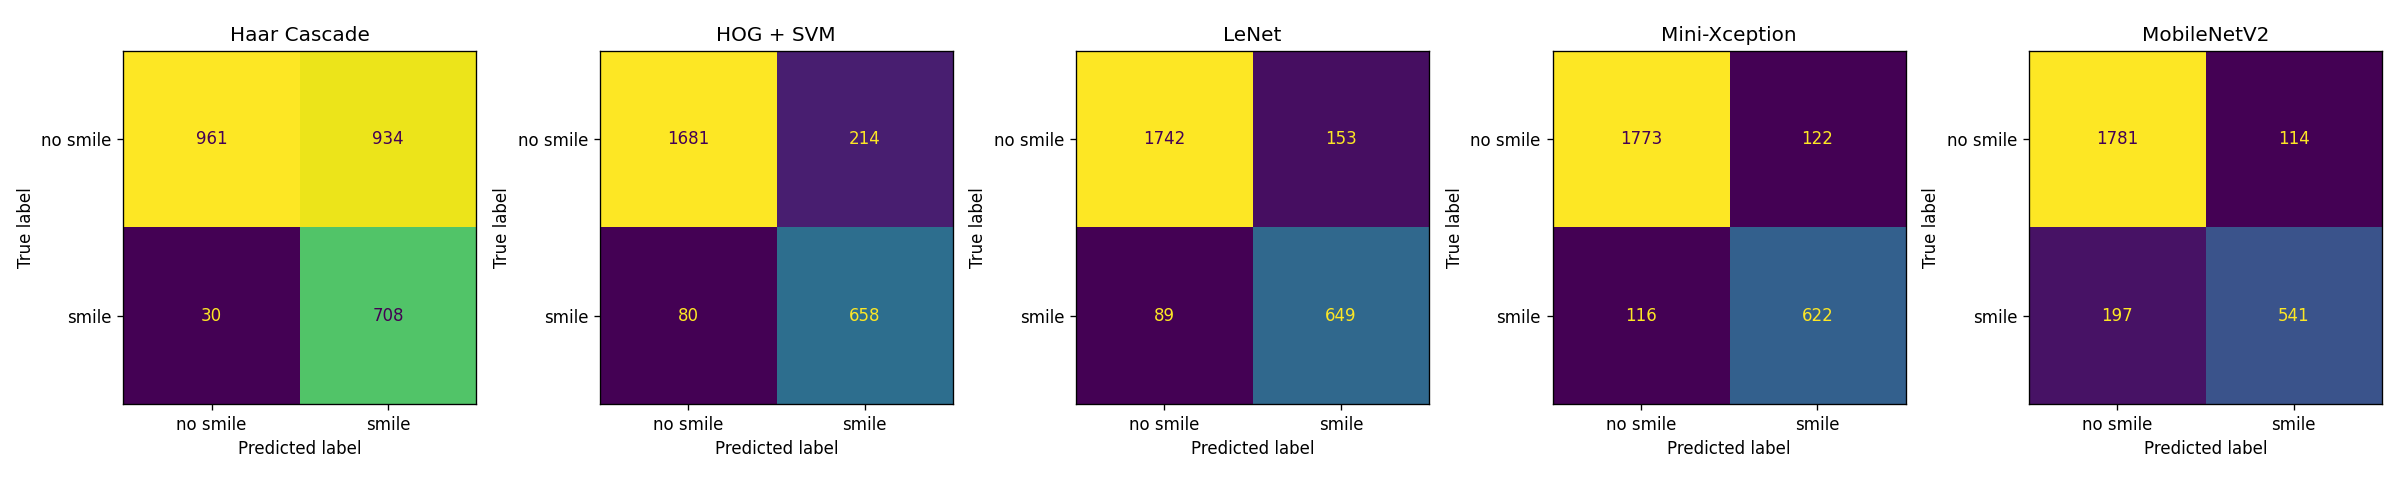

In [ ]:
!python compare_models.py

import pandas as pd
from IPython.display import Image, display
display(pd.read_csv("results.csv")[["Model", "Accuracy", "F1 (smile)", "Parameters"]].round(3))
display(Image("confusion_matrices.png"))

### 5.1 What the benchmark shows
*(Ignore the "ms / image" column: it was measured on the Colab GPU with batch prediction and warm-up included, so it doesn't reflect live, one-face-at-a-time speed on a laptop.)*

- **The Haar smile cascade fails** (~63%): brightness rectangles can't tell a smile from an open mouth.
- **HOG + SVM is a strong classic baseline** (~90%) with only ~1.8K parameters.
- **LeNet and Mini-Xception are on top** (~91–92%); Mini-Xception gets there with ~25× fewer parameters.
- **Frozen MobileNetV2 underperforms** (~87%). ImageNet features (sharp colour photos) transfer poorly to small 64×64 grayscale faces. **Transfer learning isn't automatically better**; fine-tuning the top layers would be the next step.

## 6. Deployment test on your own photos

In the live app, faces come from the **Haar face detector**, not from the dataset. Its box is looser and includes **hair and forehead**. The training faces were cropped eyebrows-to-chin, so the mouth would sit in a different place in the 28×28 input. That's a **train–deployment mismatch (domain shift)**: with the raw Haar box, a clearly smiling photo scored only ~1% "smile".

**Fix:** cut the box down to match the training framing (remove the top 20% and 18% from each side). Same model, same weights, and the same photo then scored ~99%.

Upload 1–3 photos (Ctrl/Cmd + click to select several). The labels show the confidence of the predicted class.

In [ ]:
%%writefile gradcam.py
"""
gradcam.py
Explainability: shows WHICH PART of the face made the CNN decide
"smiling" or "not smiling", as a heatmap (red = important, blue = ignored).

Three methods:
  - LayerCAM  (default, used live) - Grad-CAM variant that works better on small CNNs
  - Grad-CAM  (the classic method, kept for comparison)
  - Occlusion (cover parts of the face and measure the drop - slow but direct check)

Used in two ways:
  1. Imported by smile_selfie.py (press 'g' in the live window)
  2. Run on its own to make pictures for your report / README:

     python gradcam.py                          # random faces from dataset/  -> gradcam_examples.png
     python gradcam.py photo1.jpg photo2.png    # your own photos             -> gradcam_photos.png
     python gradcam.py --region-test            # numbers: which face region the model relies on
"""

import os
import sys
import random
import cv2
import numpy as np
import tensorflow as tf

MODEL_PATH = "smile_lenet.h5"
IMG_SIZE = 28


# ======================================================
# Grad-CAM
# ======================================================
class GradCAM:
    """
    Idea in 4 steps:
      1. Run the face through the CNN and keep the output of the LAST conv layer
         (50 feature maps of 14x14 - each map is one learned "pattern detector").
      2. Ask: "if this feature map got a bit stronger, would the decision
         get more confident?"  -> that is the GRADIENT.
      3. Average each map's gradient -> one importance weight per map.
      4. Heatmap = weighted sum of the maps (keep only positive values).
    """

    def __init__(self, model):
        self.model = model
        conv_layers = [l for l in model.layers if isinstance(l, tf.keras.layers.Conv2D)]
        self.last_conv = conv_layers[-1]          # the 2nd conv layer of LeNet (14x14x50)
        self.output_layer = model.layers[-1]      # Dense(2, softmax)

    def _forward(self, x):
        """Run the model layer by layer, remembering the last conv output.
        The final layer is computed WITHOUT softmax (raw scores = 'logits'),
        because softmax flattens the gradients when the model is very sure."""
        conv_output = None
        for layer in self.model.layers[:-1]:
            x = layer(x)
            if layer is self.last_conv:
                conv_output = x
        logits = tf.matmul(x, self.output_layer.kernel) + self.output_layer.bias
        return conv_output, logits

    def explain(self, face_input, method="layercam"):
        """face_input: array of shape (1, 28, 28, 1), values 0-1.
        method: "layercam" (default, sharper for small CNNs like LeNet) or "gradcam".
        Returns (smile_probability, heatmap 14x14 with values 0-1, predicted_class)."""
        x = tf.convert_to_tensor(face_input, dtype=tf.float32)

        with tf.GradientTape() as tape:
            conv_output, logits = self._forward(x)
            probs = tf.nn.softmax(logits)[0]
            predicted = int(tf.argmax(probs))
            # score = how much the model prefers its chosen class over the other one
            score = logits[0, predicted] - logits[0, 1 - predicted]

        grads = tape.gradient(score, conv_output)[0]           # (14, 14, 50)
        maps = conv_output[0]                                   # (14, 14, 50)

        if method == "gradcam":
            # Grad-CAM: ONE weight per map (average gradient over all positions)
            weights = tf.reduce_mean(grads, axis=(0, 1))        # (50,)
            heatmap = tf.nn.relu(tf.reduce_sum(maps * weights, axis=-1))
        else:
            # LayerCAM: a weight for EVERY position (positive gradients only).
            # LeNet uses Flatten + Dense, so each position has its own weights -
            # averaging them away (Grad-CAM) blurs the result.
            heatmap = tf.reduce_sum(tf.nn.relu(grads) * maps, axis=-1)

        heatmap = heatmap.numpy()
        heatmap = heatmap / (heatmap.max() + 1e-8)              # scale to 0-1
        return float(probs[1]), heatmap, predicted


def occlusion_map(model, face_input, patch=7, stride=3):
    """Model-independent check: cover a small grey square at every position and
    measure how much the prediction drops. Big drop = important region.
    Slower than Grad-CAM, so it's only used for the stand-alone pictures."""
    x = face_input[0]
    base = model(face_input, training=False).numpy()[0]
    predicted = int(np.argmax(base))

    covered, positions = [], []
    for i in range(0, IMG_SIZE - patch + 1, stride):
        for j in range(0, IMG_SIZE - patch + 1, stride):
            img = x.copy()
            img[i:i + patch, j:j + patch] = 0.5
            covered.append(img)
            positions.append((i, j))
    preds = model.predict(np.array(covered), verbose=0)[:, predicted]

    heat, count = np.zeros((IMG_SIZE, IMG_SIZE)), np.zeros((IMG_SIZE, IMG_SIZE))
    for (i, j), p in zip(positions, preds):
        heat[i:i + patch, j:j + patch] += base[predicted] - p
        count[i:i + patch, j:j + patch] += 1
    heat = np.maximum(heat / np.maximum(count, 1), 0)
    return heat / (heat.max() + 1e-8)


def overlay_heatmap(face_img, heatmap, alpha=0.45):
    """Colour the heatmap (blue -> red) and blend it on top of the face image."""
    if face_img.ndim == 2:                                      # grayscale -> 3 channels
        face_img = cv2.cvtColor(face_img, cv2.COLOR_GRAY2BGR)
    h, w = face_img.shape[:2]
    heat = cv2.resize(heatmap, (w, h))
    heat = cv2.applyColorMap(np.uint8(255 * heat), cv2.COLORMAP_JET)
    return cv2.addWeighted(face_img, 1 - alpha, heat, alpha, 0)


def preprocess(face_gray):
    """Same preprocessing as training: 28x28, 0-1, shape (1, 28, 28, 1)."""
    face = cv2.resize(face_gray, (IMG_SIZE, IMG_SIZE)).astype("float32") / 255.0
    return face.reshape(1, IMG_SIZE, IMG_SIZE, 1)


def remove_duplicate_faces(faces):
    """The Haar cascade sometimes returns 2 boxes for the SAME face (slightly
    shifted / different size). Keep the biggest box and drop any box whose
    centre lies inside an already-kept box."""
    faces = sorted(faces, key=lambda f: f[2] * f[3], reverse=True)
    kept = []
    for (x, y, w, h) in faces:
        cx, cy = x + w / 2, y + h / 2
        if any(kx < cx < kx + kw and ky < cy < ky + kh for (kx, ky, kw, kh) in kept):
            continue
        kept.append((x, y, w, h))
    return kept


def tight_box(x, y, w, h):
    """Cut the Haar box down to match the training framing (eyebrows to chin)."""
    return y + int(0.20 * h), y + h, x + int(0.18 * w), x + w - int(0.18 * w)


# ======================================================
# Stand-alone mode: make Grad-CAM pictures
# ======================================================
def explain_face(cam, face_gray):
    """Run all three explanation methods on one face."""
    face_input = preprocess(face_gray)
    prob, layercam, _ = cam.explain(face_input, method="layercam")
    _, gradcam, _ = cam.explain(face_input, method="gradcam")
    occlusion = occlusion_map(cam.model, face_input)
    return prob, {"Grad-CAM": gradcam, "LayerCAM": layercam, "Occlusion": occlusion}


def show_grid(items, title, out_path):
    """items: list of (face_gray, heatmaps_dict, smile_prob, caption).
    Row 1 = input face, then one row per explanation method."""
    import matplotlib.pyplot as plt

    methods = list(items[0][1].keys())
    rows, n = 1 + len(methods), len(items)
    fig, axes = plt.subplots(rows, n, figsize=(max(2.2 * n, 6), 2.3 * rows + 0.8), squeeze=False)

    for i, (face, heatmaps, prob, caption) in enumerate(items):
        big = cv2.resize(face, (140, 140))
        label = f"Smile {prob*100:.0f}%" if prob >= 0.5 else f"No smile {(1-prob)*100:.0f}%"

        axes[0, i].imshow(big, cmap="gray")
        axes[0, i].set_title(f"{caption}\n{label}", fontsize=9)
        for r, method in enumerate(methods, start=1):
            axes[r, i].imshow(cv2.cvtColor(overlay_heatmap(big, heatmaps[method]), cv2.COLOR_BGR2RGB))
        for r in range(rows):
            axes[r, i].set_xticks([])
            axes[r, i].set_yticks([])

    for r, method in enumerate(methods, start=1):
        axes[r, 0].set_ylabel(method, fontsize=10)

    fig.suptitle(title + "\n(red = region that drove the decision)")
    plt.tight_layout()
    plt.savefig(out_path, dpi=120)
    print("Saved:", out_path)
    plt.show()


def explain_dataset(cam, per_class=4):
    """Random faces from dataset/smiling and dataset/not_smiling."""
    items = []
    random.seed(1)
    for folder, name in [("smiling", "smiling"), ("not_smiling", "not smiling")]:
        path = os.path.join("dataset", folder)
        for file in random.sample(sorted(os.listdir(path)), per_class):
            face = cv2.imread(os.path.join(path, file), cv2.IMREAD_GRAYSCALE)
            if face is None:
                continue
            prob, heatmaps = explain_face(cam, face)
            items.append((face, heatmaps, prob, f"true: {name}"))
    show_grid(items, "Where does the model look? (dataset faces)", "gradcam_examples.png")


def explain_photos(cam, paths):
    """Find faces in your own photos and explain each one."""
    face_cascade = cv2.CascadeClassifier(
        cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
    items = []
    for path in paths:
        img = cv2.imread(path)
        if img is None:
            print("Could not read:", path)
            continue
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=6, minSize=(60, 60))
        faces = remove_duplicate_faces(faces)
        if len(faces) == 0:
            print("No face found in:", path)
        for (x, y, w, h) in faces:
            top, bottom, left, right = tight_box(x, y, w, h)
            face = gray[top:bottom, left:right]
            prob, heatmaps = explain_face(cam, face)
            items.append((face, heatmaps, prob, os.path.basename(path)[:18]))
    if items:
        show_grid(items, "Where does the model look? (your photos)", "gradcam_photos.png")


def region_test(cam, n_images=600):
    """Numbers for the README: which face region does the model rely on?
    1) Cover each region of confident smiles and measure the drop in smile probability.
    2) Measure what share of each heatmap falls in each region."""
    random.seed(0)
    files = random.sample(sorted(os.listdir("dataset/smiling")), n_images)
    X = np.array([cv2.resize(cv2.imread(os.path.join("dataset/smiling", f), 0), (IMG_SIZE, IMG_SIZE))
                  for f in files]).astype("float32")[..., None] / 255.0
    p = cam.model.predict(X, verbose=0)[:, 1]
    X, p = X[p >= 0.8], p[p >= 0.8]
    print(f"Confident smiles tested: {len(X)}\n")

    regions = {"forehead": (0, 7), "eyes": (7, 14), "nose": (14, 19), "mouth+chin": (19, 28)}

    print("1) Cover a region -> average smile probability")
    for name, (a, b) in regions.items():
        covered = X.copy()
        covered[:, a:b] = X.mean()
        p_cov = cam.model.predict(covered, verbose=0)[:, 1]
        print(f"   {name:11s} {p.mean():.2f} -> {p_cov.mean():.2f}   (drop {p.mean() - p_cov.mean():.2f})")

    print("\n2) Share of heatmap in each region (first 100 faces)")
    for method in ["gradcam", "layercam", "occlusion"]:
        mass = np.zeros(len(regions))
        for x in X[:100]:
            if method == "occlusion":
                h = occlusion_map(cam.model, x[None])
            else:
                h = cv2.resize(cam.explain(x[None], method=method)[1], (IMG_SIZE, IMG_SIZE))
            for k, (a, b) in enumerate(regions.values()):
                mass[k] += h[a:b].sum()
        shares = "  ".join(f"{n} {s*100:.0f}%" for n, s in zip(regions, mass / mass.sum()))
        print(f"   {method:10s} {shares}")


if __name__ == "__main__":
    model = tf.keras.models.load_model(MODEL_PATH)
    cam = GradCAM(model)

    if len(sys.argv) > 1 and sys.argv[1] == "--region-test":
        region_test(cam)
    elif len(sys.argv) > 1:
        explain_photos(cam, sys.argv[1:])
    else:
        explain_dataset(cam)


Writing gradcam.py


Saving image1.png to image1 (1).png


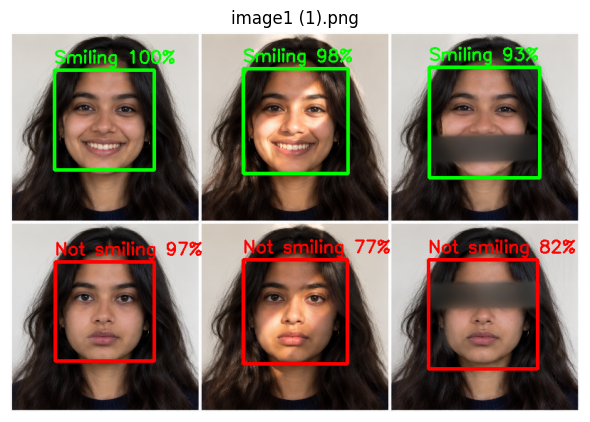

image1 (1).png                 Smiling 93%   (P(smile) = 0.93)
image1 (1).png                 Not smiling 82%   (P(smile) = 0.18)
image1 (1).png                 Smiling 98%   (P(smile) = 0.98)
image1 (1).png                 Not smiling 77%   (P(smile) = 0.23)
image1 (1).png                 Smiling 100%   (P(smile) = 1.00)
image1 (1).png                 Not smiling 97%   (P(smile) = 0.03)


In [ ]:
import cv2
import matplotlib.pyplot as plt
from google.colab import files
from tensorflow.keras.models import load_model
from gradcam import tight_box, remove_duplicate_faces, preprocess

model = load_model("smile_lenet.h5")
face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
THRESHOLD = 0.80

uploaded = files.upload()
results, summary = [], []

for filename in uploaded:
    img = cv2.imread(filename)
    if img is None:
        print(f"{filename}: could not read (use .jpg or .png)")
        continue
    scale = 800 / max(img.shape[:2])                    # shrink big phone photos
    if scale < 1:
        img = cv2.resize(img, None, fx=scale, fy=scale)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    faces = remove_duplicate_faces(
        face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=6, minSize=(60, 60)))
    if len(faces) == 0:
        summary.append(f"{filename:30s} no face found")

    for (x, y, w, h) in faces:
        top, bottom, left, right = tight_box(x, y, w, h)      # match the training framing
        prob = float(model(preprocess(gray[top:bottom, left:right]), training=False)[0, 1])
        smiling = prob >= THRESHOLD
        color = (0, 255, 0) if smiling else (0, 0, 255)
        label = f"Smiling {prob*100:.0f}%" if smiling else f"Not smiling {(1-prob)*100:.0f}%"
        cv2.rectangle(img, (x, y), (x + w, y + h), color, 3)
        cv2.putText(img, label, (x, max(y - 10, 20)), cv2.FONT_HERSHEY_SIMPLEX, 0.8, color, 2)
        summary.append(f"{filename:30s} {label}   (P(smile) = {prob:.2f})")
    results.append((filename, img))

if results:
    fig, axes = plt.subplots(1, len(results), figsize=(6 * len(results), 6), squeeze=False)
    for ax, (name, img) in zip(axes[0], results):
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(name)
        ax.axis("off")
    plt.tight_layout()
    plt.show()
print("\n".join(summary))

## 7. Explainability I: where does the model look? (gradient methods)

A model can be accurate for the **wrong reasons** (background, lighting, glasses). Explainability methods show *which pixels drove a decision*.

**Grad-CAM, the idea:** the last conv layer has 50 feature maps ("pattern detectors"). For each one, ask: *if this map got stronger, would the decision get more confident?* That's the **gradient**. Grad-CAM averages it into **one weight per map**, then overlays the weighted maps as a heatmap.

**LayerCAM** keeps a weight for **every position** instead of averaging. That matters for LeNet: its **Flatten + Dense** layers give each position its own weights, so averaging (Grad-CAM) throws location information away.

**Occlusion** doesn't look inside the model at all: it covers a grey square at every position and measures how much the prediction drops. Slow, but direct evidence.

The `--region-test` covers whole face regions of confident smiles and checks which region the model really needs.

W0000 00:00:1795257148.201110   19549 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
Saved: gradcam_examples.png
Figure(1760x1000)
W0000 00:00:1795257162.136905   19775 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
Confident smiles tested: 473

1) Cover a region -> average smile probability
   forehead    0.96 -> 0.96   (drop 0.00)
   eyes        0.96 -> 0.93   (drop 0.04)
   nose        0.96 -> 0.95   (drop 0.01)
   mouth+chin  0.96 -> 0.21   (drop 0.75)

2) Share of heatmap in each region (first 100 faces)
   gradcam    forehead 22%  eyes 26%  nose 15%  mouth+chin 36%
   layercam   forehead 11%  eyes 14%  nose 21%  mouth+chin 54%
   occlusion  forehead 2%  eyes 9%  nose 23%  mouth+chin 65%


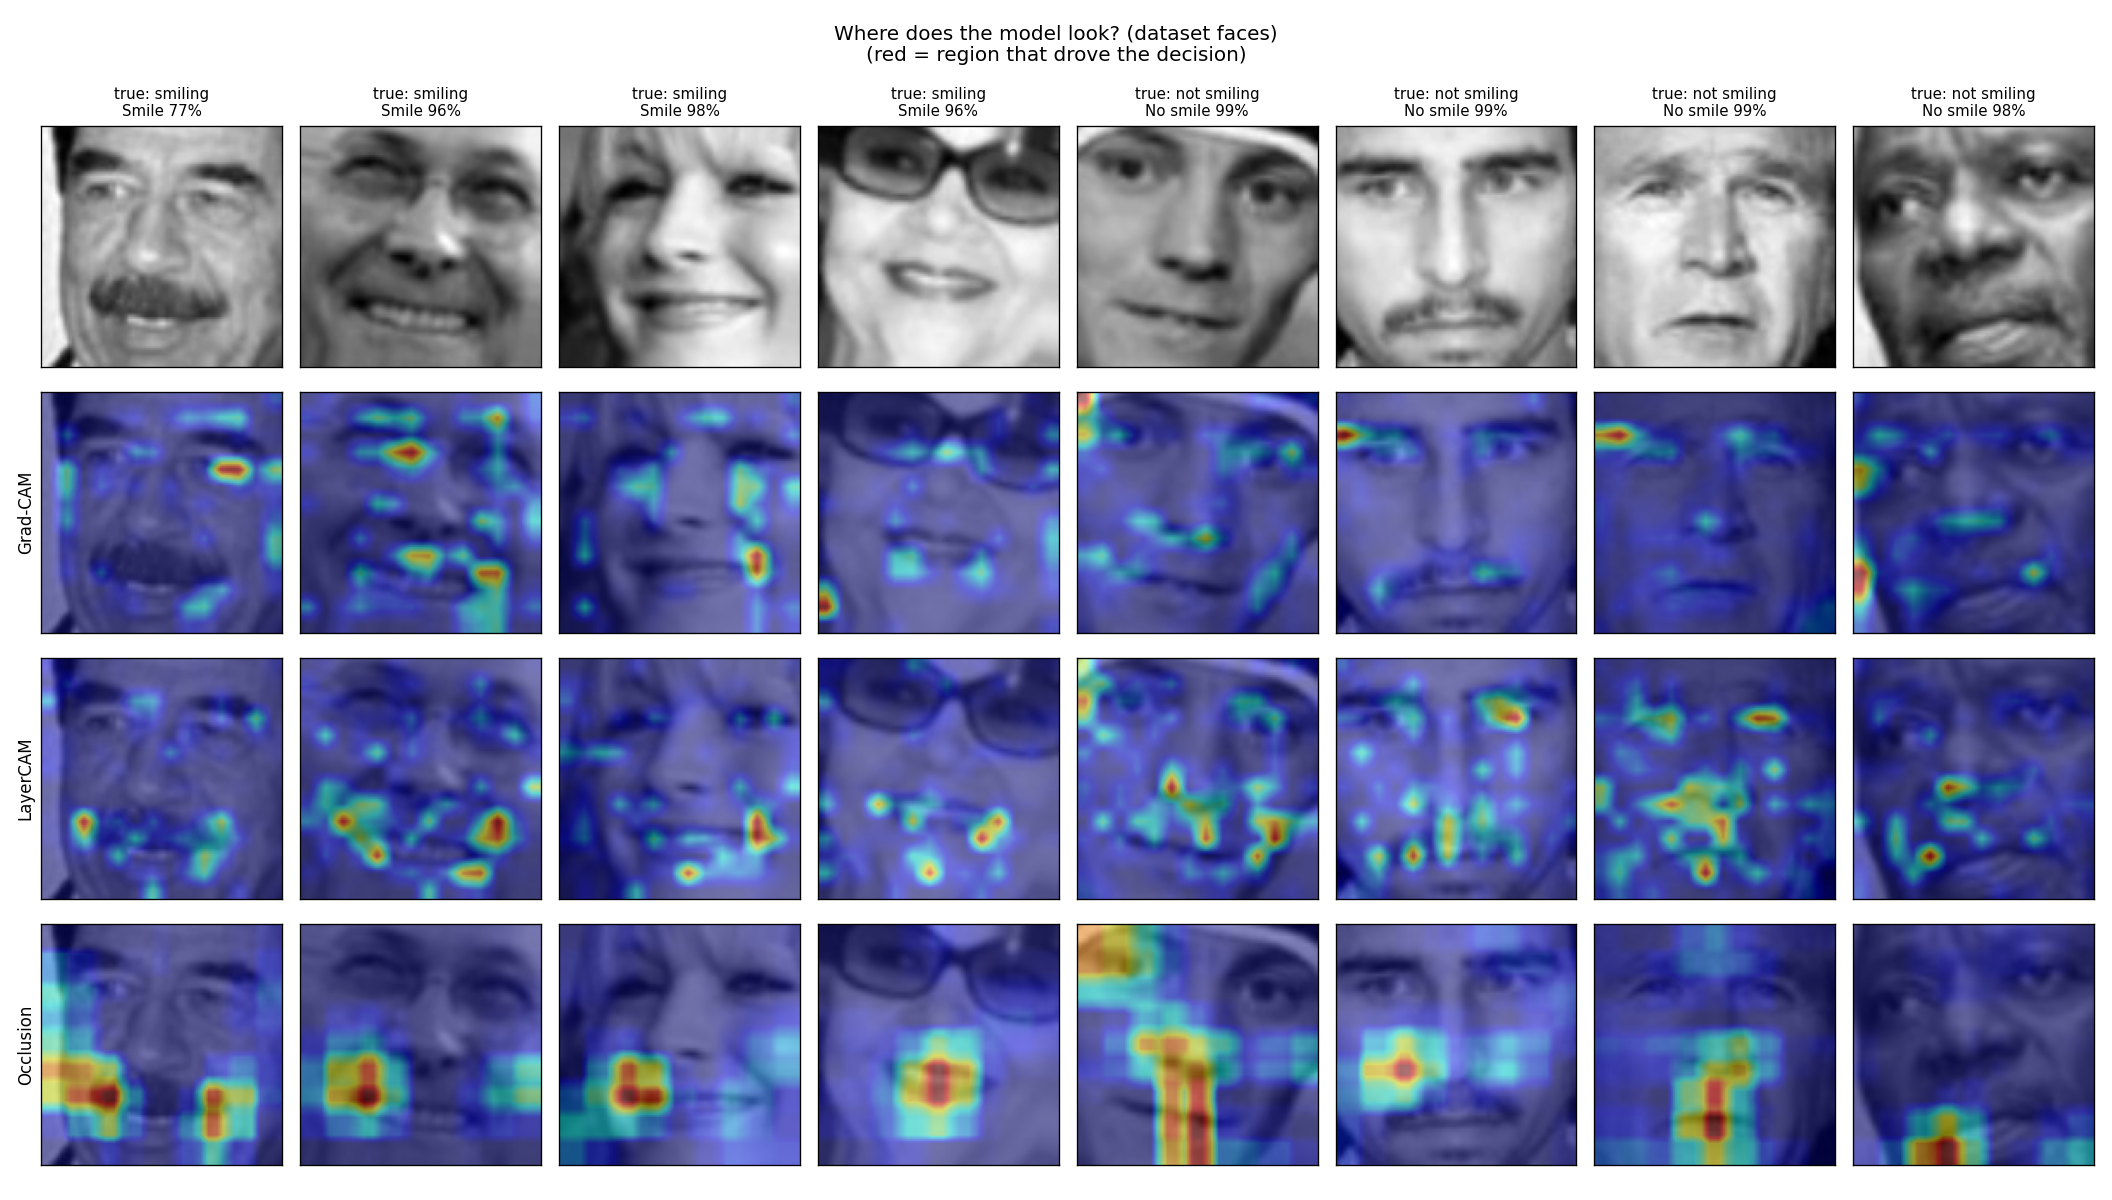

In [ ]:
!python gradcam.py
!python gradcam.py --region-test

from IPython.display import Image
Image("gradcam_examples.png")

### 7.1 Reading the result
- **Region test:** if covering the *mouth* collapses the smile probability while covering eyes, nose or forehead barely changes it, the model genuinely relies on the mouth.
- **Grad-CAM vs LayerCAM:** Grad-CAM tends to look scattered on LeNet; LayerCAM and occlusion concentrate on the lips and mouth corners. A popular method can give a **misleading** explanation if its assumptions don't fit the architecture, which is why Part 8 checks the explanations themselves.

## 8. Explainability II: LIME, SHAP, and can we trust the explanations?

Both methods are **model-agnostic**: they treat the CNN as a black box and only change the input. They work on any model, even HOG + SVM.

**LIME (superpixels):**
1. Cut the face into ~40 **superpixels** (natural regions of similar brightness).
2. Make 1,000 copies with random superpixels greyed out.
3. Ask the model for each copy's prediction.
4. Fit a simple **linear model**: *score ≈ w₁·region₁ + w₂·region₂ + …*. The weights are the explanation.

**SHAP (Shapley values, from game theory):** treat regions as *players in a team*. Each region's SHAP value is its **fair average contribution** over many team line-ups. Two useful properties: the contributions **add up** to the prediction, and they can be **positive** (supports the decision, red) or **negative** (against it, blue).

Explanations are computed on a 64×64 view (superpixels need room); every perturbed image is shrunk to 28×28 before the model sees it, exactly like real inputs.

In [ ]:
%%writefile explain.py
"""
explain.py
Model-agnostic explanations (LIME and SHAP) for the smile model,
and a faithfulness check that compares ALL explanation methods.

Model-agnostic = these methods never look inside the CNN. They only change
the input image and watch how the output changes, so they work on any model.

  LIME  - cuts the face into superpixels (natural regions), hides random
          combinations of them, and fits a simple linear model:
          "smile score ~ w1*region1 + w2*region2 + ..."  -> the weights explain.
  SHAP  - game theory (Shapley values): the fair average contribution of
          every region, over many combinations. Contributions ADD UP to the
          prediction and can be positive (pro-smile) or negative (anti-smile).

Run:
  python explain.py                  # 8 dataset faces -> explain_lime_shap.png
  python explain.py photo1.jpg ...   # your own photos -> explain_photos.png
  python explain.py --faithfulness   # which method focuses where (all methods)
"""

import os
import sys
import contextlib
import random
import warnings
import cv2
import numpy as np
import tensorflow as tf

from gradcam import (GradCAM, occlusion_map, preprocess, tight_box,
                     remove_duplicate_faces, IMG_SIZE)

warnings.filterwarnings("ignore")

MODEL_PATH = "smile_lenet.h5"
VIEW = 64                 # explanations work on a 64x64 view (superpixels need room)
LIME_SAMPLES = 1000       # how many perturbed copies LIME creates per face
SHAP_EVALS = 500          # how many model calls SHAP may use per face

# face regions on the 28x28 grid (rows) - used for the faithfulness check
REGIONS = {"forehead": (0, 7), "eyes": (7, 14), "nose": (14, 19), "mouth+chin": (19, 28)}


# ======================================================
# A "black box" predict function: what LIME and SHAP talk to
# ======================================================
def make_predict_fn(model):
    """Takes a batch of 64x64 RGB images (values 0-1), returns [P(no smile), P(smile)].
    Inside, it does exactly the training preprocessing: gray, 28x28."""
    def predict(images):
        images = np.asarray(images, dtype="float32")
        gray = images[..., 0] if images.ndim == 4 else images     # all 3 channels are equal
        small = np.array([cv2.resize(g, (IMG_SIZE, IMG_SIZE)) for g in gray])
        return model.predict(small[..., None], verbose=0, batch_size=256)
    return predict


def to_view(face_gray):
    """Gray face (any size, 0-255) -> 64x64 RGB float image in 0-1."""
    face = cv2.resize(face_gray, (VIEW, VIEW)).astype("float32") / 255.0
    return np.stack([face] * 3, axis=-1)


# ======================================================
# LIME
# ======================================================
def lime_explain(predict, view_img, label):
    """Returns (heatmap 64x64 of superpixel weights, segments)."""
    from lime import lime_image
    from lime.wrappers.scikit_image import SegmentationAlgorithm

    # ~40 superpixels of similar brightness (compactness keeps them roundish)
    segmenter = SegmentationAlgorithm("slic", n_segments=40, compactness=10, sigma=1, start_label=0)
    explainer = lime_image.LimeImageExplainer(random_state=0)
    with open(os.devnull, "w") as quiet, contextlib.redirect_stderr(quiet):   # hide LIME's progress bar
        explanation = explainer.explain_instance(
            view_img.astype("double"), predict, labels=(label,), top_labels=None,
            hide_color=0.5, num_samples=LIME_SAMPLES, segmentation_fn=segmenter,
            batch_size=256,
        )
    segments = explanation.segments
    heat = np.zeros(segments.shape, dtype="float32")
    for seg_id, weight in explanation.local_exp[label]:
        heat[segments == seg_id] = weight
    return heat, segments


# ======================================================
# SHAP
# ======================================================
def shap_explain(predict, view_img, label):
    """Returns a 64x64 map of SHAP values for the given class
    (positive = pushes towards that class, negative = pushes away)."""
    import shap

    masker = shap.maskers.Image("blur(16,16)", view_img.shape)   # hidden parts get blurred
    explainer = shap.Explainer(predict, masker, output_names=["no smile", "smile"])
    sv = explainer(view_img[None], max_evals=SHAP_EVALS, batch_size=100,
                   outputs=[label], silent=True)
    return sv.values[0, ..., 0].sum(axis=-1)          # sum the 3 (identical) channels


# ======================================================
# All methods for one face
# ======================================================
def explain_all(model, cam, predict, face_gray):
    """Run every method on one face. Returns (smile_prob, label, dict of maps).
    Maps are float arrays; LIME/SHAP are signed, the others are 0-1."""
    face_input = preprocess(face_gray)
    prob, layercam, label = cam.explain(face_input, method="layercam")
    view_img = to_view(face_gray)
    lime_map, segments = lime_explain(predict, view_img, label)
    return prob, label, {
        "LayerCAM": layercam,
        "Occlusion": occlusion_map(model, face_input),
        "LIME": lime_map,
        "SHAP": shap_explain(predict, view_img, label),
    }, segments


# ======================================================
# Figure
# ======================================================
def show_grid(items, title, out_path):
    """items: list of (face_gray, prob, maps, segments, caption)."""
    import matplotlib.pyplot as plt
    from skimage.segmentation import mark_boundaries

    methods = ["LayerCAM", "Occlusion", "LIME", "SHAP"]
    rows, n = 1 + len(methods), len(items)
    fig, axes = plt.subplots(rows, n, figsize=(max(2.2 * n, 7), 2.3 * rows + 0.9), squeeze=False)

    for i, (face, prob, maps, segments, caption) in enumerate(items):
        view = cv2.resize(face, (VIEW, VIEW))
        label = f"Smile {prob*100:.0f}%" if prob >= 0.5 else f"No smile {(1-prob)*100:.0f}%"
        axes[0, i].imshow(view, cmap="gray")
        axes[0, i].set_title(f"{caption}\n{label}", fontsize=9)

        for r, method in enumerate(methods, start=1):
            ax = axes[r, i]
            heat = cv2.resize(maps[method].astype("float32"), (VIEW, VIEW))
            if method in ("LIME", "SHAP"):
                # signed: red = supports the prediction, blue = against it
                if method == "LIME":
                    ax.imshow(mark_boundaries(np.stack([view / 255.0] * 3, -1), segments,
                                              color=(1, 1, 0), mode="thin"))
                else:
                    ax.imshow(view, cmap="gray")
                lim = np.abs(heat).max() + 1e-8
                ax.imshow(heat, cmap="bwr", vmin=-lim, vmax=lim, alpha=0.55)
            else:
                ax.imshow(view, cmap="gray")
                ax.imshow(heat, cmap="jet", alpha=0.45, vmin=0, vmax=1)

    for r in range(rows):
        for i in range(n):
            axes[r, i].set_xticks([])
            axes[r, i].set_yticks([])
    for r, method in enumerate(methods, start=1):
        axes[r, 0].set_ylabel(method, fontsize=10)

    fig.suptitle(title + "\nLayerCAM/Occlusion: red = important.   "
                 "LIME/SHAP: red = supports the prediction, blue = against it "
                 "(LIME shows superpixel borders)", fontsize=10)
    plt.tight_layout()
    plt.savefig(out_path, dpi=120)
    print("Saved:", out_path)
    plt.show()


def explain_dataset(model, cam, predict, per_class=4):
    items = []
    random.seed(1)
    for folder, name in [("smiling", "smiling"), ("not_smiling", "not smiling")]:
        path = os.path.join("dataset", folder)
        for file in random.sample(sorted(os.listdir(path)), per_class):
            face = cv2.imread(os.path.join(path, file), cv2.IMREAD_GRAYSCALE)
            if face is None:
                continue
            prob, _, maps, segments = explain_all(model, cam, predict, face)
            items.append((face, prob, maps, segments, f"true: {name}"))
    show_grid(items, "Model-agnostic vs gradient explanations (dataset faces)",
              "explain_lime_shap.png")


def explain_photos(model, cam, predict, paths):
    face_cascade = cv2.CascadeClassifier(
        cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
    items = []
    for path in paths:
        img = cv2.imread(path)
        if img is None:
            print("Could not read:", path)
            continue
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=6, minSize=(60, 60))
        faces = remove_duplicate_faces(faces)
        if len(faces) == 0:
            print("No face found in:", path)
        for (x, y, w, h) in faces:
            top, bottom, left, right = tight_box(x, y, w, h)
            face = gray[top:bottom, left:right]
            prob, _, maps, segments = explain_all(model, cam, predict, face)
            items.append((face, prob, maps, segments, os.path.basename(path)[:18]))
    if items:
        show_grid(items, "Model-agnostic vs gradient explanations (your photos)",
                  "explain_photos.png")


# ======================================================
# Faithfulness check: where does each method put its attention?
# ======================================================
def faithfulness(model, cam, predict, n_faces=40):
    """For confident smiles, measure the share of POSITIVE evidence each
    method puts in each face region. The occlusion region test in gradcam.py
    showed the model relies on the mouth, so a faithful method should
    put most of its evidence there."""
    import pandas as pd

    random.seed(0)
    files = random.sample(sorted(os.listdir("dataset/smiling")), 300)
    faces = []
    for f in files:
        face = cv2.imread(os.path.join("dataset/smiling", f), cv2.IMREAD_GRAYSCALE)
        if face is not None and float(model(preprocess(face), training=False)[0, 1]) >= 0.8:
            faces.append(face)
        if len(faces) == n_faces:
            break
    print(f"Testing {len(faces)} confidently smiling faces (LIME and SHAP take a few seconds each)...")

    methods = ["Grad-CAM", "LayerCAM", "Occlusion", "LIME", "SHAP"]
    mass = {m: np.zeros(len(REGIONS)) for m in methods}
    for k, face in enumerate(faces, 1):
        face_input = preprocess(face)
        view_img = to_view(face)
        maps = {
            "Grad-CAM": cam.explain(face_input, method="gradcam")[1],
            "LayerCAM": cam.explain(face_input, method="layercam")[1],
            "Occlusion": occlusion_map(model, face_input),
            "LIME": lime_explain(predict, view_img, 1)[0],
            "SHAP": shap_explain(predict, view_img, 1),
        }
        for m, heat in maps.items():
            heat = cv2.resize(np.maximum(heat, 0).astype("float32"), (IMG_SIZE, IMG_SIZE),
                              interpolation=cv2.INTER_AREA)       # positive evidence on 28x28
            for j, (a, b) in enumerate(REGIONS.values()):
                mass[m][j] += heat[a:b].sum()
        if k % 10 == 0:
            print(f"  {k}/{len(faces)} done")

    table = pd.DataFrame({m: 100 * mass[m] / mass[m].sum() for m in methods},
                         index=list(REGIONS)).T.round(0)
    area = {r: 100 * (b - a) / IMG_SIZE for r, (a, b) in REGIONS.items()}
    table.loc["(share of image area)"] = [round(v) for v in area.values()]
    print("\nShare of positive evidence per face region (%):")
    print(table.to_string())
    table.to_csv("faithfulness.csv")
    print("\nSaved: faithfulness.csv")
    return table


if __name__ == "__main__":
    model = tf.keras.models.load_model(MODEL_PATH)
    cam = GradCAM(model)
    predict = make_predict_fn(model)

    if len(sys.argv) > 1 and sys.argv[1] == "--faithfulness":
        faithfulness(model, cam, predict)
    elif len(sys.argv) > 1:
        explain_photos(model, cam, predict, sys.argv[1:])
    else:
        explain_dataset(model, cam, predict)


Writing explain.py


W0000 00:00:1795257738.150720   23301 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
Saved: explain_lime_shap.png
Figure(1760x1240)


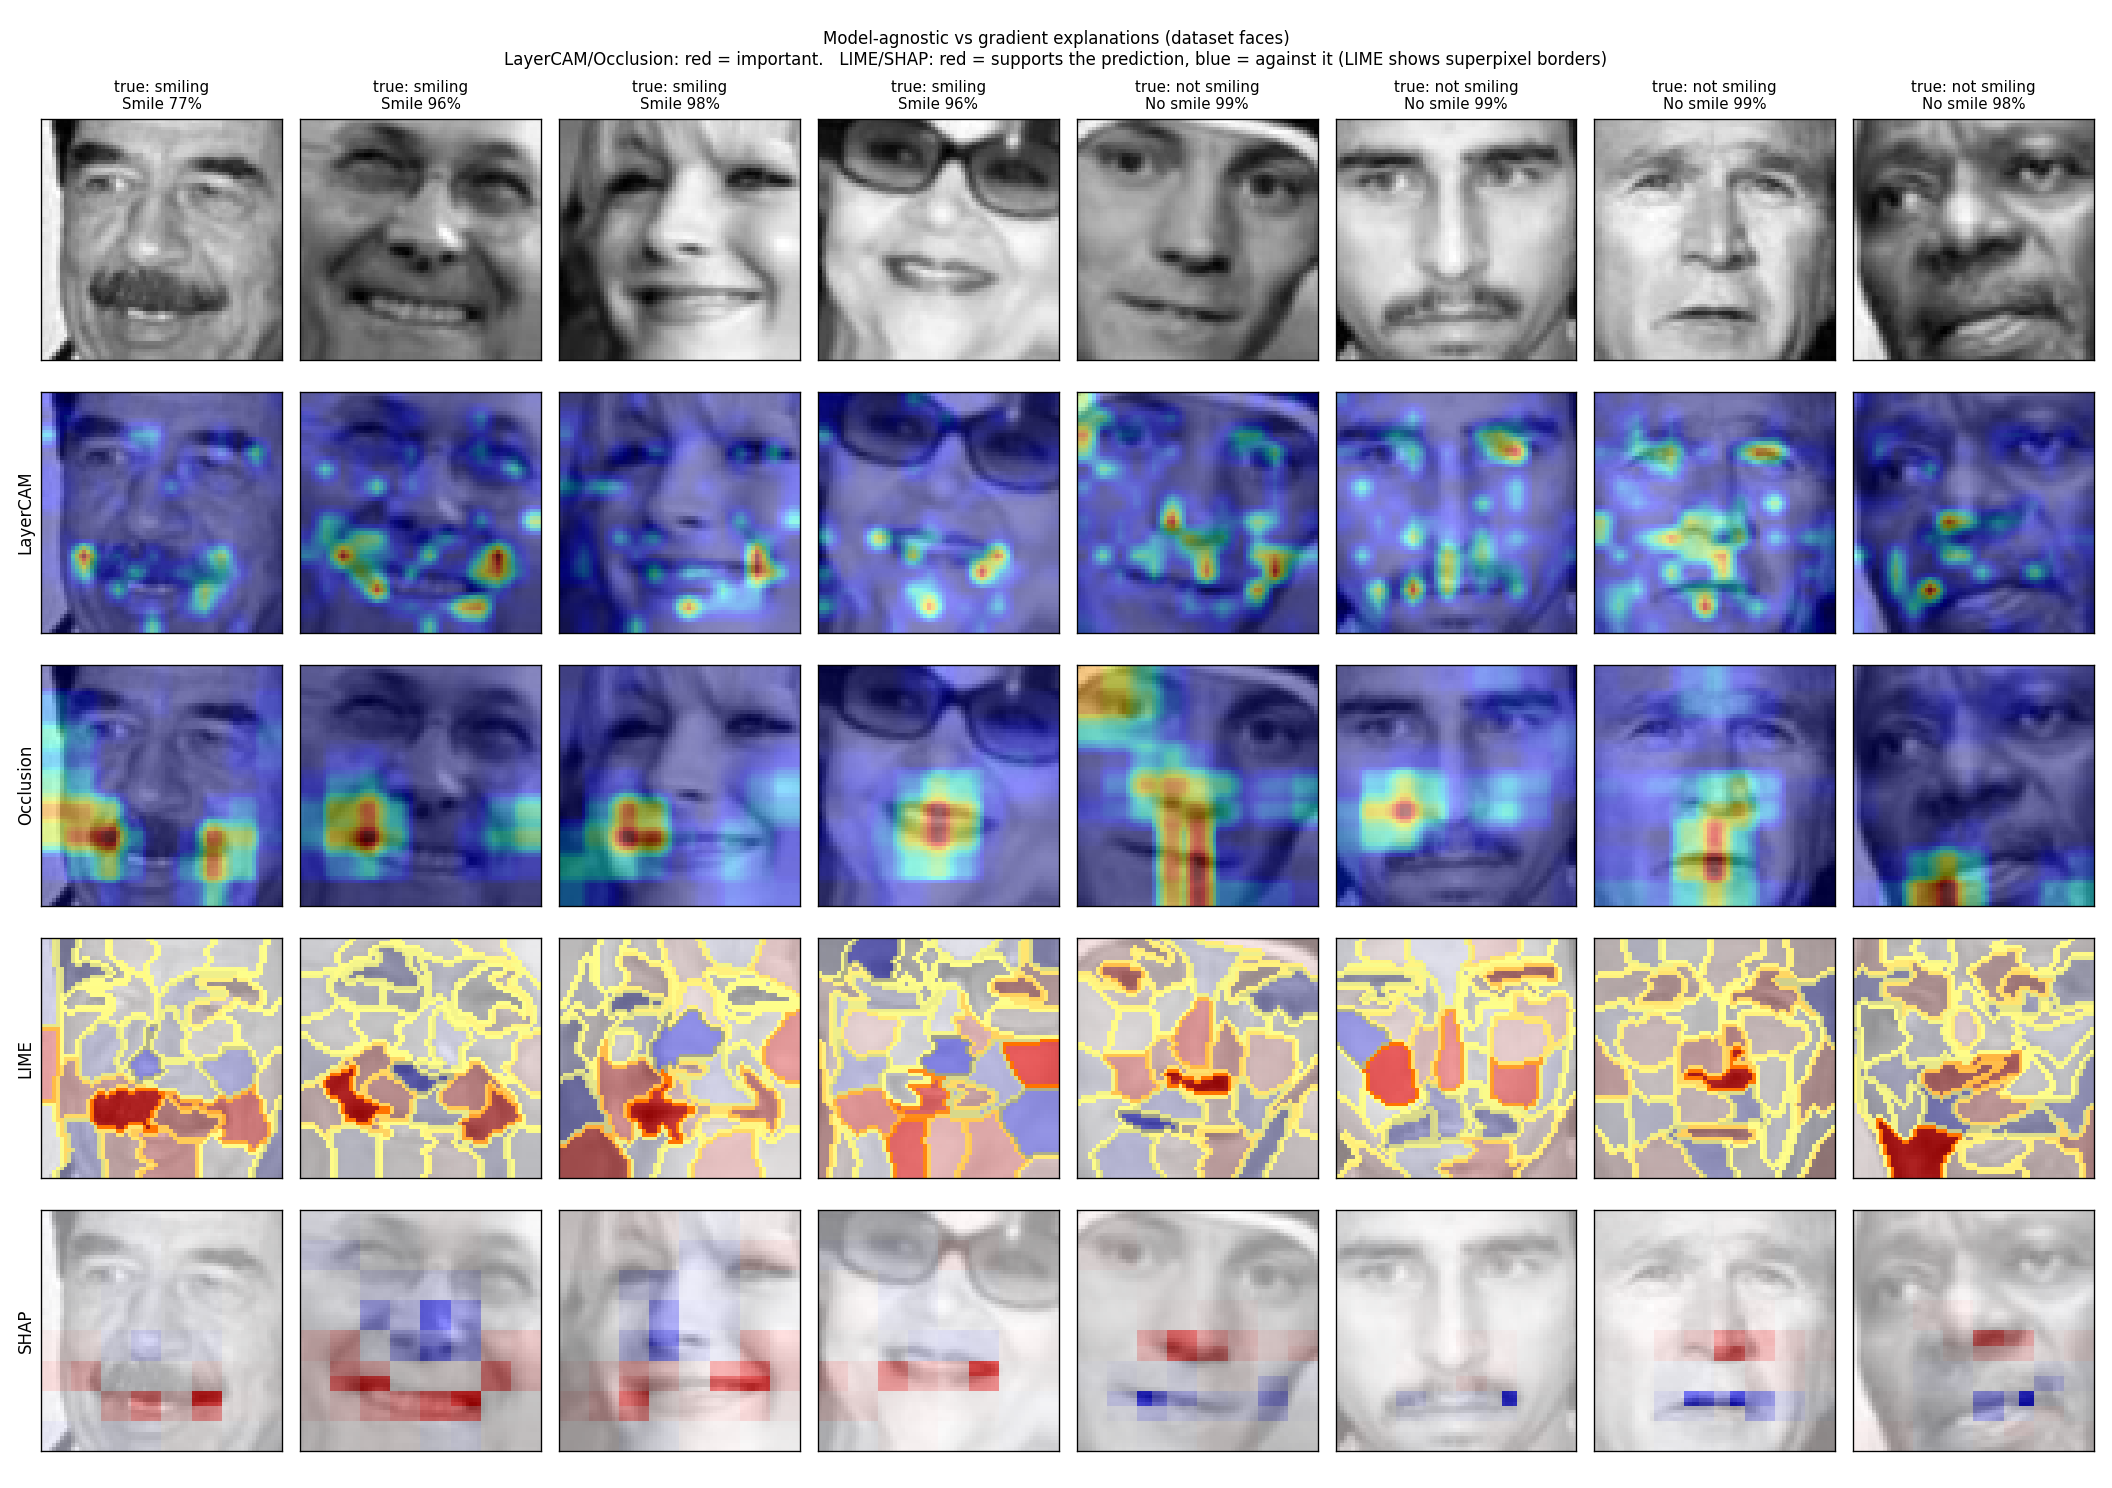

In [ ]:
!python explain.py

from IPython.display import Image
Image("explain_lime_shap.png")

### 8.1 Faithfulness check: do the methods agree with the evidence?
For 40 confidently smiling faces, this measures the share of each method's **positive evidence** in each face region. The last row is each region's share of the image area (what you'd get if a method spread its attention evenly).

A **faithful** method should agree with the direct evidence from the region test (the mouth). Methods that disagree are telling you more about their own assumptions than about the model. *Takes ~2–3 minutes.*

In [ ]:
!python explain.py --faithfulness

import pandas as pd
pd.read_csv("faithfulness.csv", index_col=0)

W0000 00:00:1795258093.973856   26164 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
Testing 40 confidently smiling faces (LIME and SHAP take a few seconds each)...
  10/40 done
  20/40 done
  30/40 done
  40/40 done

Share of positive evidence per face region (%):
                       forehead  eyes  nose  mouth+chin
Grad-CAM                   22.0  26.0  16.0        36.0
LayerCAM                   12.0  13.0  20.0        55.0
Occlusion                   3.0   8.0  21.0        68.0
LIME                        5.0   8.0  18.0        69.0
SHAP                        2.0   2.0  13.0        84.0
(share of image area)      25.0  25.0  18.0        32.0

Saved: faithfulness.csv


,forehead,eyes,nose,mouth+chin
Grad-CAM,22.0,26.0,16.0,36.0
LayerCAM,12.0,13.0,20.0,55.0
Occlusion,3.0,8.0,21.0,68.0
LIME,5.0,8.0,18.0,69.0
SHAP,2.0,2.0,13.0,84.0
(share of image area),25.0,25.0,18.0,32.0


**Optional:** run LIME and SHAP on your own photos.

Saving image1.png to image1 (2).png
W0000 00:00:1795258257.974270   32092 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
Saved: explain_photos.png
Figure(1540x1240)


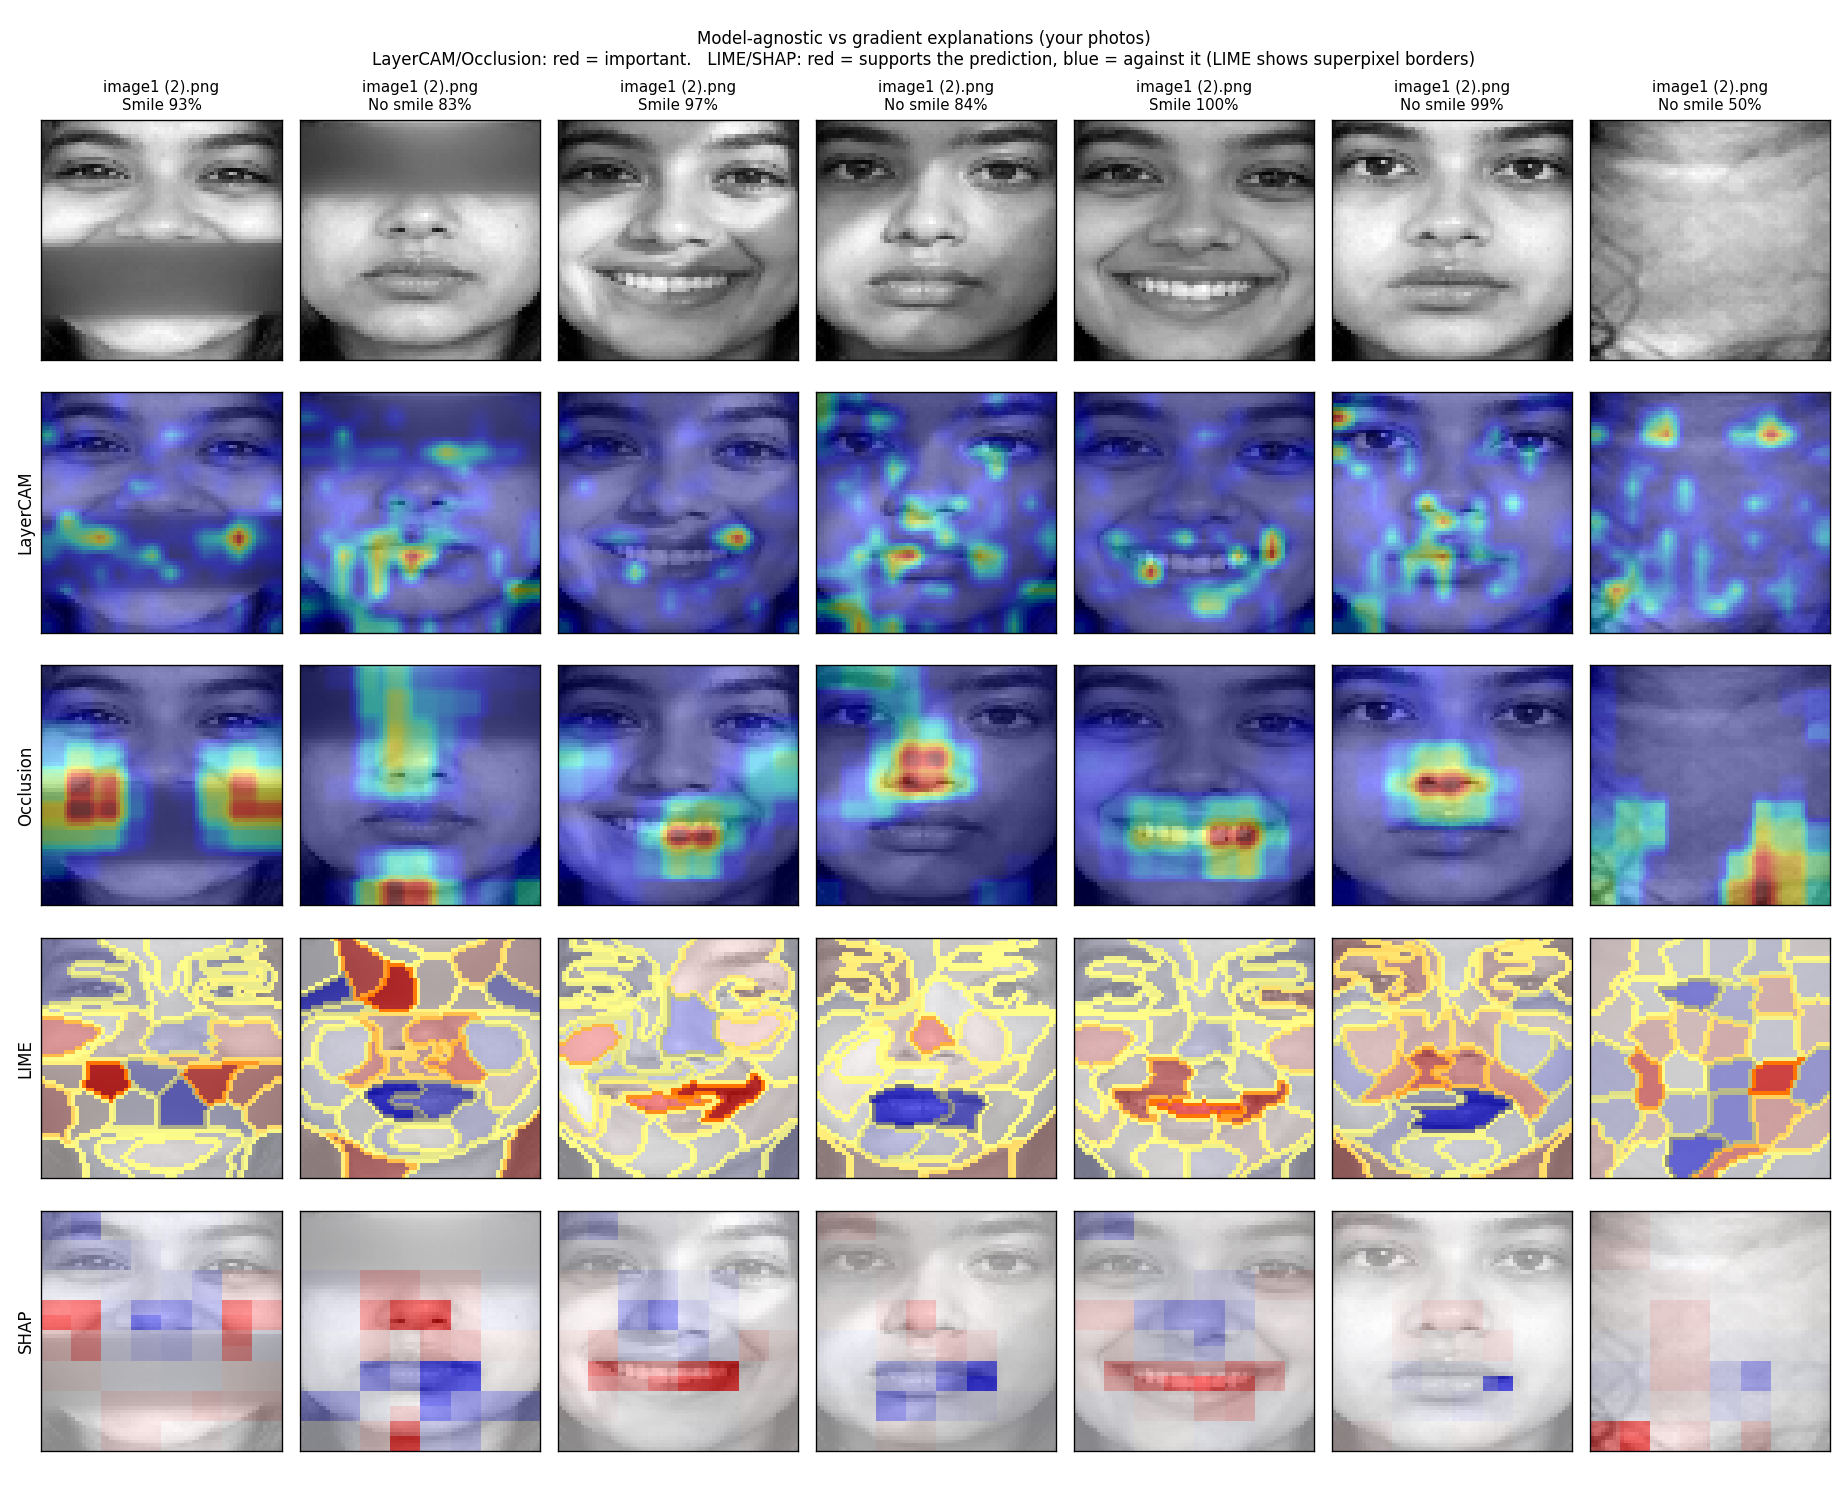

In [ ]:
from google.colab import files
from IPython.display import Image, display

uploaded = files.upload()
names = " ".join(f'"{n}"' for n in uploaded)
!python explain.py {names}
display(Image("explain_photos.png"))

In [ ]:
import os
from google.colab import files

!zip -q results.zip smile_lenet.h5 training_plot.png results.csv comparison_chart.png confusion_matrices.png gradcam_examples.png explain_lime_shap.png faithfulness.csv 2>/dev/null
print("Included:", [f for f in ["smile_lenet.h5", "training_plot.png", "results.csv", "comparison_chart.png",
                                "confusion_matrices.png", "gradcam_examples.png", "explain_lime_shap.png",
                                "faithfulness.csv"] if os.path.exists(f)])
files.download("results.zip")

Included: ['smile_lenet.h5', 'training_plot.png', 'results.csv', 'comparison_chart.png', 'confusion_matrices.png', 'gradcam_examples.png', 'explain_lime_shap.png', 'faithfulness.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>